# Bring your own simulations

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `ebd964ed89e4`](https://github.com/OJWatson/metis/tree/ebd964ed89e468e4f03197f2c0217c581e294b97).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("ebd964ed89e468e4f03197f2c0217c581e294b97")


Start with a table containing one row per **simulation run and timepoint**.
This example creates a small CSV so you can run every cell before substituting
your own file. For local setup, see [installation](https://ojwatson.github.io/metis/basics/installing_metis.html).

## A small example bank

The toy simulator tracks a stock with decay and external forcing. Every time
step it applies $s_{t+1}=(1-d)s_t+f+\epsilon_t$, starting at $s_0=10$.
Noise is independently drawn from $N(0,0.1^2)$. Its flux is
$d s_t+\eta_t$, with independent $N(0,0.05^2)$ noise. This gives 30 parameter
settings, three replicates each and 12 timepoints; it is a data-handling exercise.

In [1]:
#| code-fold: true
#| code-summary: "Create the example simulation bank"
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch

from metis import SimulationDataset, Surrogate, TrainingConfig

torch.set_num_threads(2)
output = Path("own-bank-output")
output.mkdir(exist_ok=True)
rng = np.random.default_rng(42)
rows = []
for decay in np.linspace(0.05, 0.5, 6):
    for forcing in np.linspace(0.2, 1.0, 5):
        for rep in range(3):
            stock = 10.0
            for t in range(12):
                flux = decay * stock + rng.normal(0, 0.05)
                rows.append(dict(decay=decay, forcing=forcing, rep=rep,
                                 t=t, stock=stock, flux=flux))
                stock = (1 - decay) * stock + forcing + rng.normal(0, 0.1)
pl.DataFrame(rows).write_csv(output / "bank.csv")

## Tell METIS which columns mean what

`inputs` are constant within a run; `outputs` vary with time. Here `rep` identifies
a replicate and `t` identifies a timepoint. Replicates with the same inputs are
kept together when splitting the bank.

In [2]:
frame = pl.read_csv(output / "bank.csv")
frame.head().to_pandas()

,decay,forcing,rep,t,stock,flux
0,0.05,0.2,0,0,10.000000,0.515236
1,0.05,0.2,0,1,9.596002,0.517323
2,0.05,0.2,0,2,9.410258,0.372961
3,0.05,0.2,0,3,9.009527,0.456868
4,0.05,0.2,0,4,8.727427,0.435531


In [3]:
bank = SimulationDataset.from_frame(
    frame,
    inputs=["decay", "forcing"],
    outputs=["stock", "flux"],
)
print(f"Validated {len(bank)} runs, {len(bank.times)} timepoints and {len(bank.output_names)} outputs")

Validated 90 runs, 12 timepoints and 2 outputs


For your own data, change the CSV path and these two column lists. METIS checks
for missing values, duplicate run/time rows and inconsistent time grids.
See the [data contract](https://ojwatson.github.io/metis/package/data.html) if your identifiers or layout differ.

## Train and inspect the result

In [4]:
split = bank.split(validation_fraction=0.2, test_fraction=0.2, seed=42)
model = Surrogate("mlp").fit(
    split.train, split.validation,
    config=TrainingConfig(steps=500, eval_every=50, seed=42),
)
report = model.evaluate(split.test)
report.by_output.to_pandas().round(3)

,output,rmse,mae
0,stock,0.308,0.224
1,flux,0.097,0.082


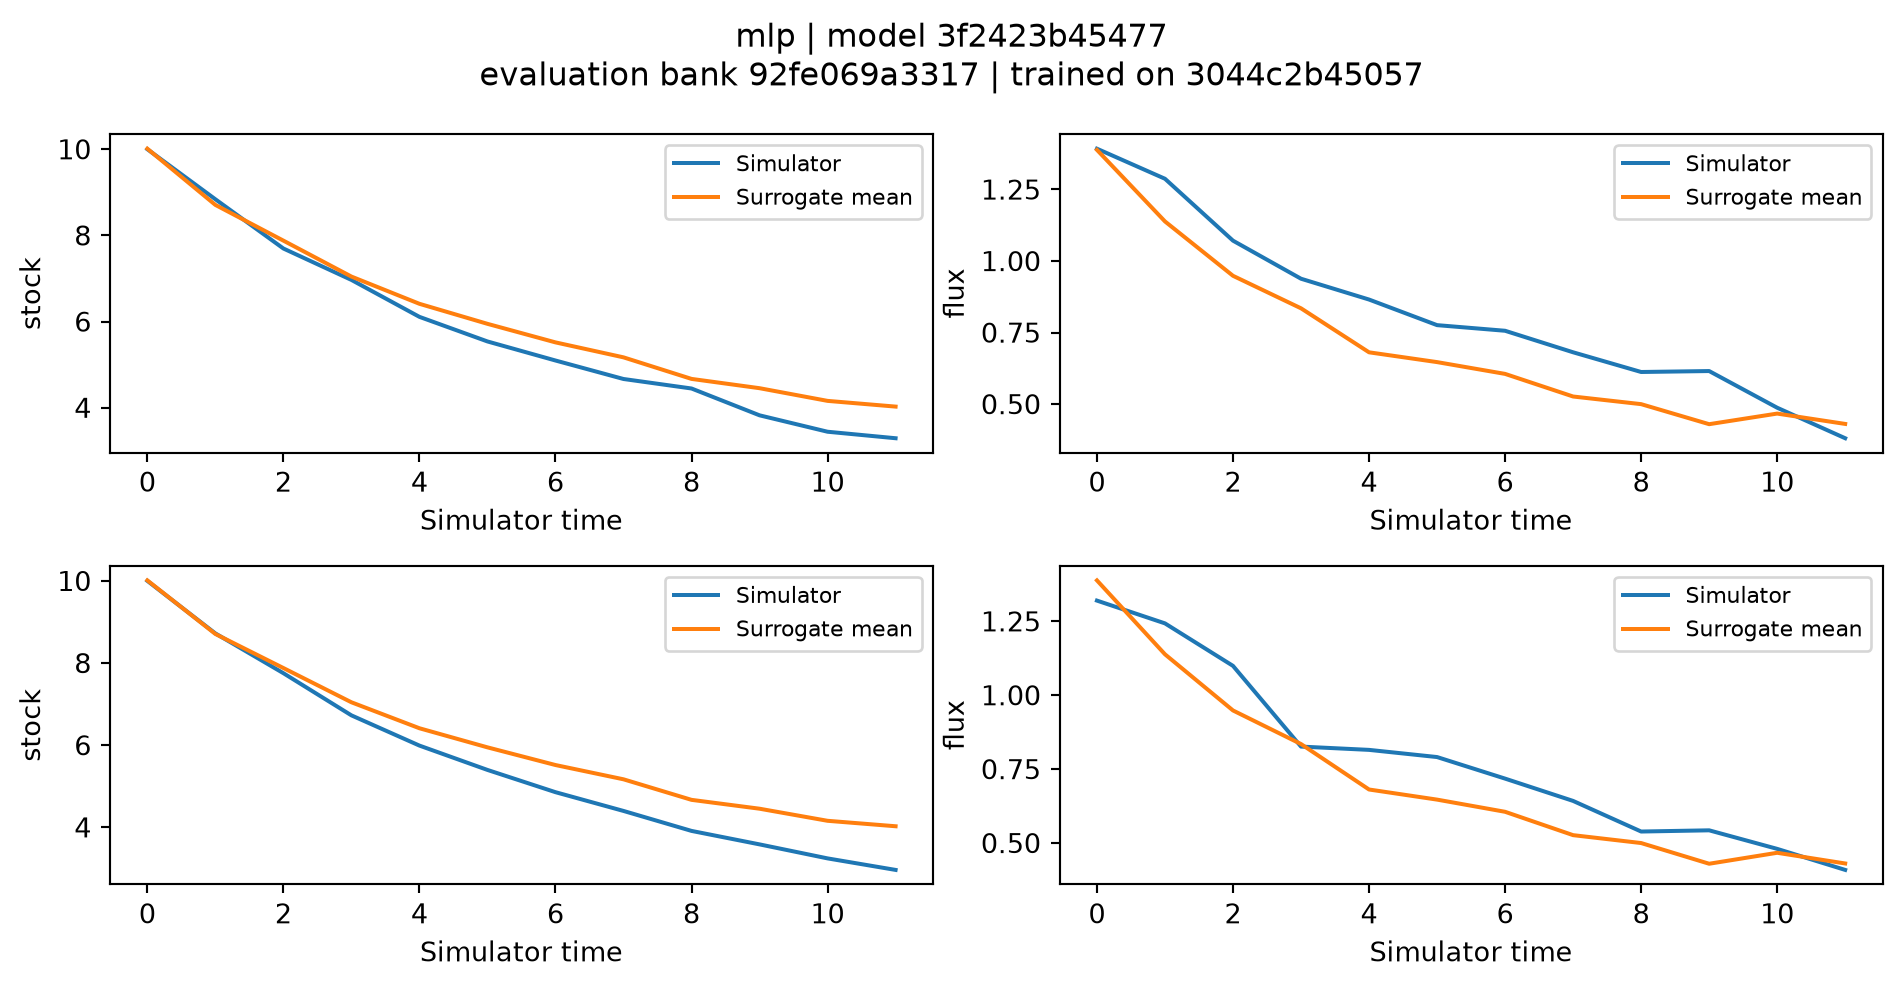

In [5]:
#| label: fig-own-bank-test
#| fig-cap: 'MLP fitted to the synthetic stock/flux training partition: predictions for two held-out test realizations.'
fig = report.plot(max_runs=2)
plt.show()

*MLP fitted to the synthetic stock/flux training partition: predictions for two held-out test realizations.*

The model predicts a typical trajectory rather than individual noise draws.
Use the errors in stock and flux units to decide whether it suits your task.
[Stochastic surrogates](https://ojwatson.github.io/metis/package/model-choice.html) can generate multiple realizations.

## Reuse it elsewhere

In [6]:
model.save(output / "model.pt")
report.save(output / "evaluation.json")
restored = Surrogate.load(output / "model.pt")
query = dict(zip(bank.input_names, split.test.inputs[0].tolist()))
prediction = restored.predict(query)
print("Query:", query)
print("Prediction shape:", prediction.shape)
np.testing.assert_allclose(prediction, model.predict(query))

Query: {'decay': 0.14000000059604645, 'forcing': 0.20000000298023224}
Prediction shape: (1, 12, 2)


Copy `model.pt` to your dashboard or analysis project. With METIS installed, the
last four lines work without the training CSV. Replace `query` with values for
your model's inputs; preserve their meaning and units.